# Simulation

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import HTML
import matplotlib 
matplotlib.rc('font', family='serif')
matplotlib.rc('font', serif='STIXGeneral')
from cmcrameri import cm  #cmap=cm.lipari 
matplotlib.rcParams['animation.embed_limit'] = 50  # MB

### Global variables

In [19]:
matrix_height = 1600
matrix_width = 2550
radius = 50
Y, X = np.ogrid[:matrix_height, :matrix_width]

## Object & background 

In [8]:

def make_object_linear_3(t):
    '''creates a linear moving object'''
    Obj = np.zeros((matrix_height, matrix_width))
    # Object  (horizontal linear)
    x_move = int(centre_x)
    y_move = int(centre_y + amp_x * np.sin(t))
    
    moving_x.append(x_move)
    moving_y.append(y_move)
    
    Obj[y_move, x_move] = 1
    mask = (X - x_move)**2 + (Y - y_move)**2 <= radius**2
    Obj[mask] = 255

    x_move_2 = int(centre_x + amp_x * np.sin(t+2))
    y_move_2 = int(centre_y)
    
    moving_x_2.append(x_move_2)
    moving_y_2.append(y_move_2)
    
    Obj[y_move_2, x_move_2] = 1
    mask_2 = (X - x_move_2)**2 + (Y - y_move_2)**2 <= radius**2
    Obj[mask_2] = 255

    return Obj

### Animation

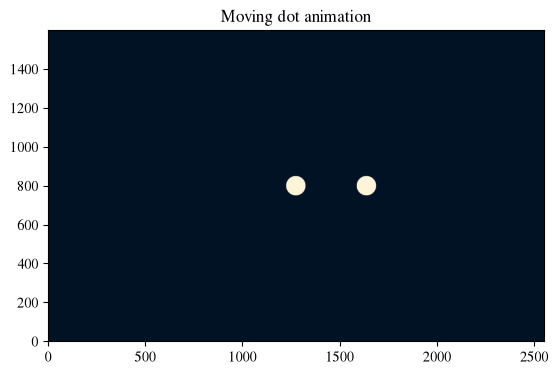

In [20]:
moving_x = []
moving_y = []

moving_x_2 = []
moving_y_2 = []

centre_x = matrix_width // 2
centre_y = matrix_height // 2
seperation = 300
amp_x = 400
amp_y = 400
noframes = 20
# animation
fig, ax = plt.subplots()
img = ax.imshow(make_object_linear_3(0), origin='lower',cmap=cm.lipari )
ax.set_title("Moving dot animation")


def animation_make_object_3(frame):
    '''inputs value for t to make each image frame'''
    t = 2 * np.pi * frame / noframes
    img.set_data(make_object_linear_3(t))
    return [img]

del moving_x[-1]
del moving_y[-1]


animation = FuncAnimation(fig, animation_make_object_3, frames=noframes, interval=100)


HTML(animation.to_jshtml())

In [29]:
from PIL import Image

# Load GIF from your files
tracking_gif = Image.open("C:\\Users\\Student\\OneDrive - University of Exeter\\Desktop\\Imaging & tracking objects behind a scattering medium\\data\\cross correlation tracking\\tracking_video_scaled.gif")
# Extract all frames from the GIF
frames = []

for i in range(tracking_gif.n_frames):
    tracking_gif.seek(i)
    frames.append(tracking_gif.convert("RGBA").copy())

# Create your subplots
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

'''# Subplot 1: Your normal image
ax[0].imshow(plt.imread("my_image.png"))
ax[0].set_title("Static image")
ax[0].axis("off")
'''
# Subplot 2: Your animated GIF
im = ax[1].imshow(frames[0])
ax[1].set_title("Animated GIF")
ax[1].axis("off")

# Function to update the GIF frame
def update(frame):
    im.set_data(frames[frame])
    return [im]

# Create the animation
ani = FuncAnimation(
    fig,
    update,
    frames=len(frames),
    interval=100,
    blit=True
)

plt.tight_layout()

# Display the animation in Jupyter
plt.close(fig)
display(HTML(ani.to_jshtml()))